In [25]:
from kilosort import run_kilosort, DEFAULT_SETTINGS
from kilosort.io import save_probe, load_ops, load_probe

import os
import numpy as np
import pandas as pd
import glob
import re
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import gridspec, rcParams
rcParams['axes.spines.top'] = False
rcParams['axes.spines.right'] = False

import spikeinterface.core as sc
from probeinterface import Probe
from probeinterface.plotting import plot_probe

from pixelbat.utils import parse_file_structure, readTrodesExtractedDataFile

In [2]:
import spikeinterface.extractors as se


In [4]:
data_path = r'C:\Users\Batlab\Desktop\Kevin\35580\250806\35580_250806_MEC_g1'

#data_path = r'C:\Users\Batlab\Desktop\Kevin\35580\250806\35580_250806_ref_ext_g0\35580_250806_ref_ext_g0_imec0'
data_path = r'X:\users\Kevin\datasets\GridBat\14731\cage_sleep\raw\250812\14731_250812_264_good_g0\14731_250812_264_good_g0_imec0'

In [5]:
rec = se.read_spikeglx(folder_path=data_path, stream_name='imec0.ap')


In [6]:
rec

SpikeGLXRecordingExtractor: 384 channels - 30.0kHz - 1 segments - 132,091,623 samples 
                            4,403.05s (1.22 hours) - int16 dtype - 94.48 GiB

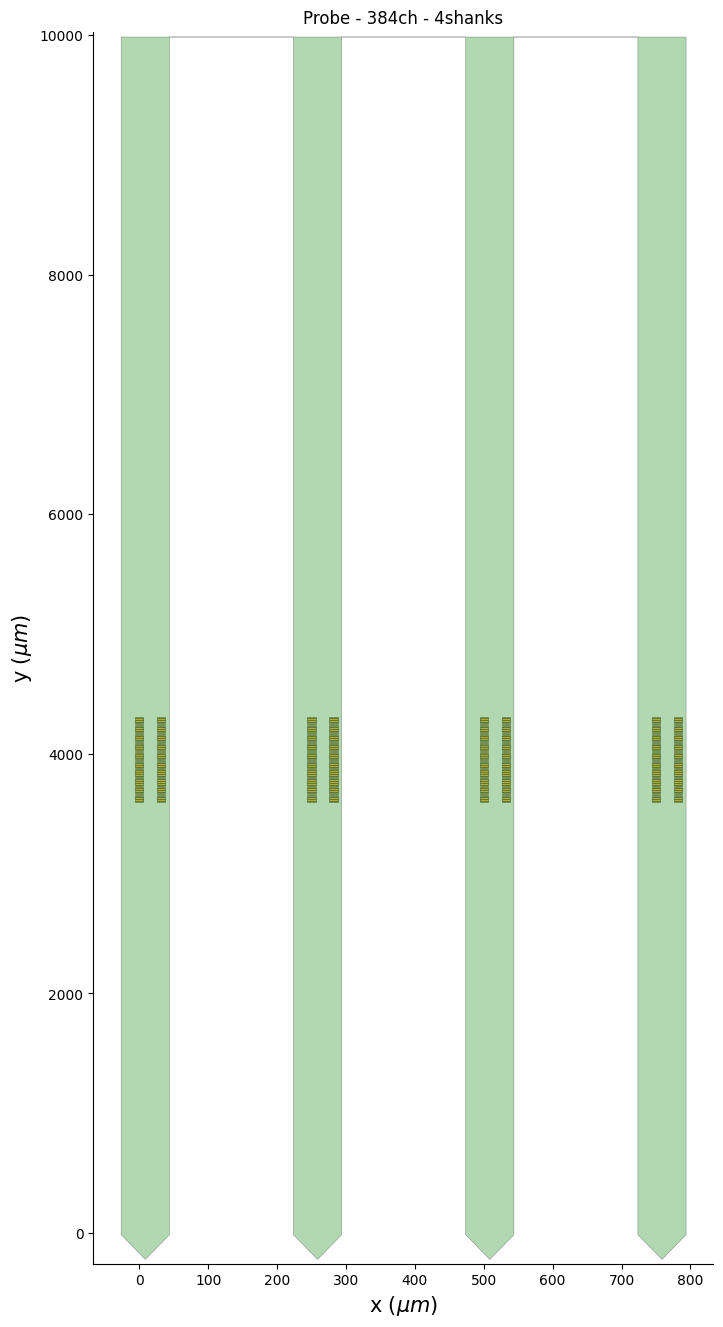

In [7]:
fig, ax = plt.subplots(figsize=(8, 16))
plot_probe(rec.get_probe(), ax=ax, with_device_index=False)
#ax.set_title(f'Probe {iProbe+1} (Note, Device Index is reversed from Trodes Index)')
ax.set_aspect('auto')
plt.show()


In [8]:
recordings = [rec]
iProbe = 0

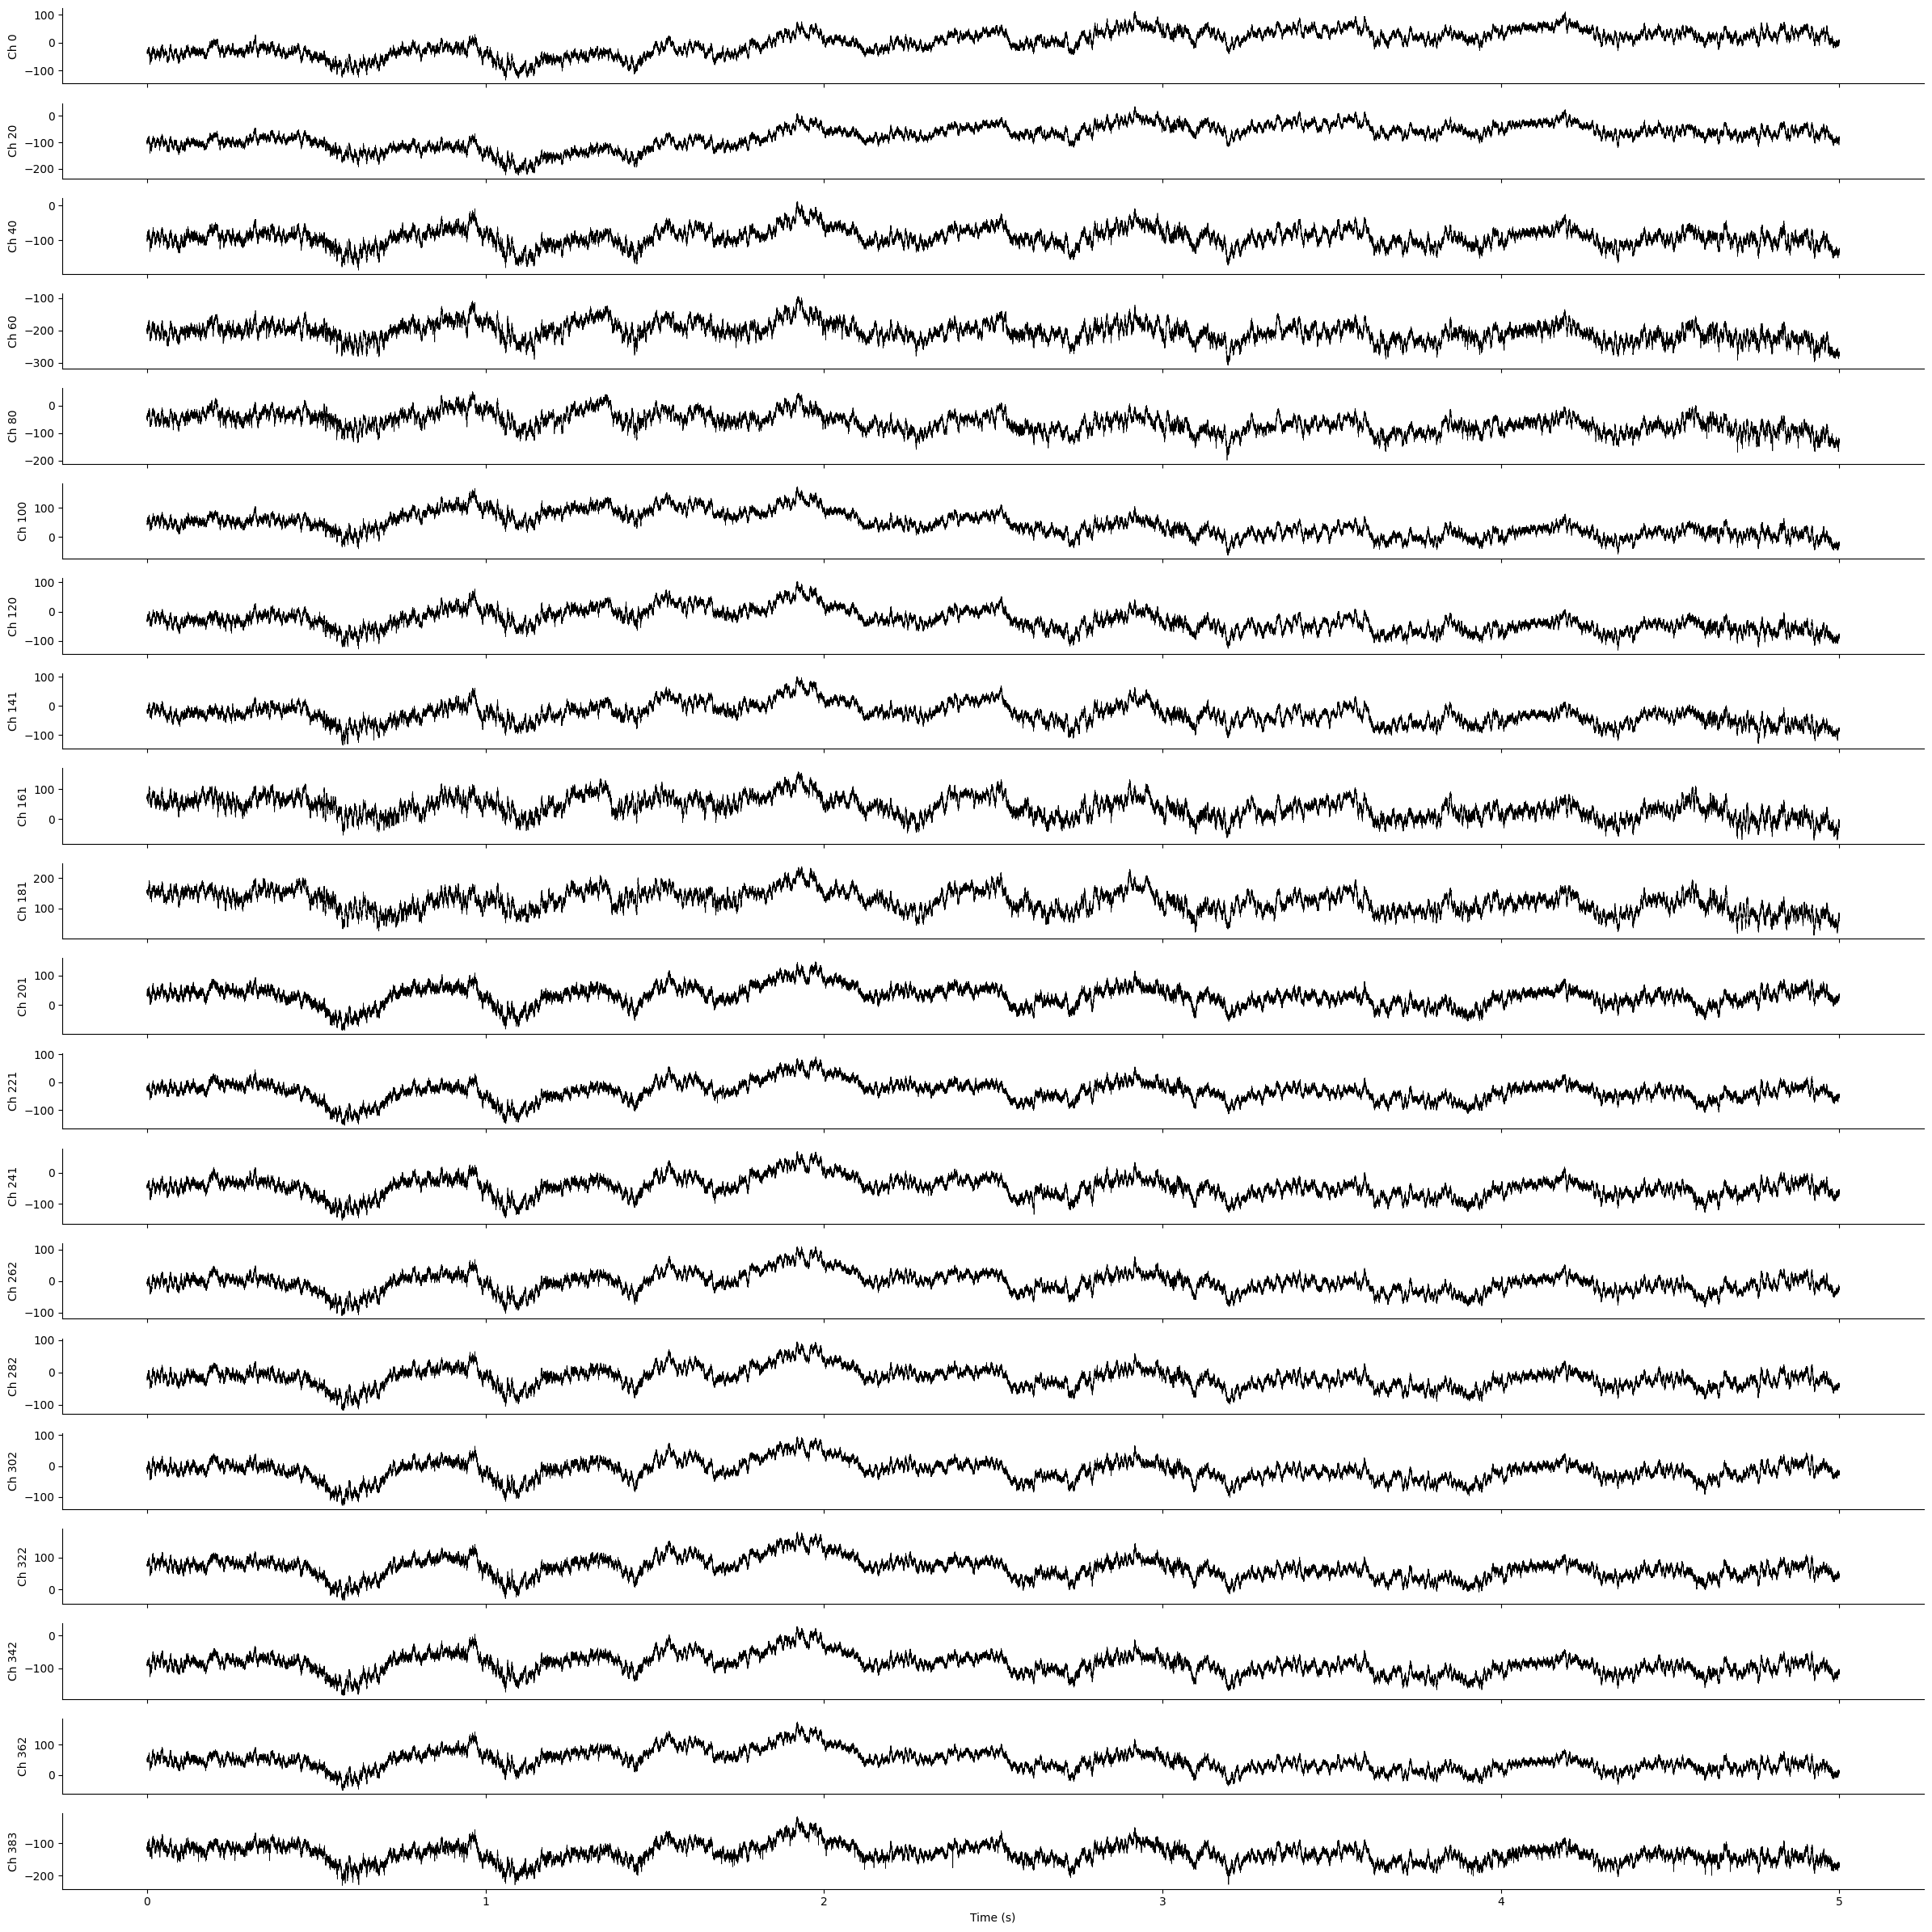

In [17]:
    # Plot short 1 second traces from 10 evenly sampled channels
    fig, axes = plt.subplots(20, 1, figsize=(24, 24), sharex=True)
    
    # Get recording data
    recording = recordings[iProbe]
    fs = recording.get_sampling_frequency()
    total_channels = recording.get_num_channels()
    
    # Sample 10 channels evenly across all channels
    channel_indices = np.linspace(0, total_channels-1, 20, dtype=int)
    
    # Get 1 second of data (starting from 10 seconds to avoid startup artifacts)
    start_sample = int(300 * fs)
    end_sample = int(305 * fs)
    traces = recording.get_traces(start_frame=start_sample, end_frame=end_sample, 
                                 channel_ids=recording.get_channel_ids()[channel_indices])
    
    # Time vector
    time = np.arange(traces.shape[0]) / fs
    
    # Plot each channel
    for i, ch_idx in enumerate(channel_indices):
        axes[i].plot(time, traces[:, i], 'k-', linewidth=0.5)
        axes[i].set_ylabel(f'Ch {ch_idx}')
        axes[i].spines['top'].set_visible(False)
        axes[i].spines['right'].set_visible(False)
    
    axes[-1].set_xlabel('Time (s)')
    plt.tight_layout()
    plt.show()


In [19]:
from spikeinterface.preprocessing import bandpass_filter, common_reference, phase_shift


In [20]:
rec_f = bandpass_filter(recording=rec, freq_min=300, freq_max=6000)
rec_shift = phase_shift(recording=rec_f)
rec_cmr = common_reference(recording=rec_f, operator="median", reference="global")

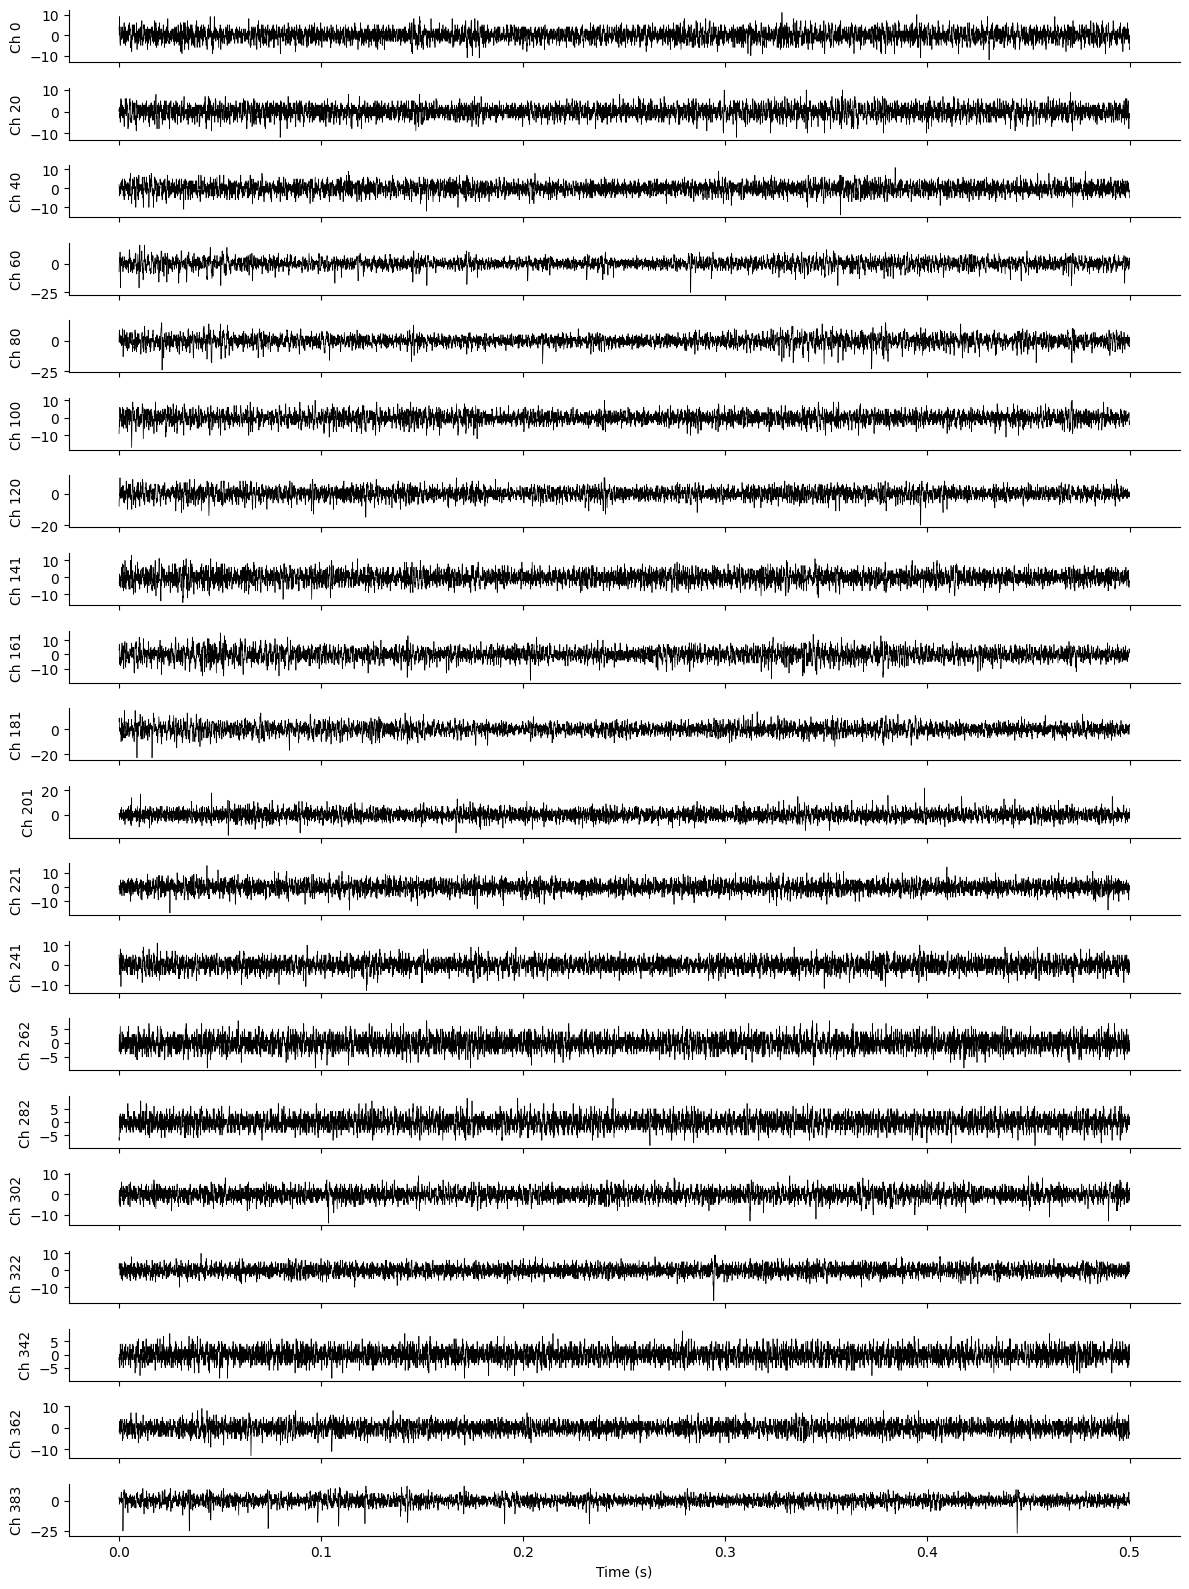

In [21]:
    # Plot short 1 second traces from 20 evenly sampled channels
    fig, axes = plt.subplots(20, 1, figsize=(12, 16), sharex=True)
    
    # Get recording data
    recording = rec_cmr
    fs = recording.get_sampling_frequency()
    total_channels = recording.get_num_channels()
    
    # Sample 20 channels evenly across all channels
    channel_indices = np.linspace(0, total_channels-1, 20, dtype=int)
    
    # Get 1 second of data (starting from 10 seconds to avoid startup artifacts)
    start_sample = int(100 * fs)
    end_sample = int(100.5 * fs)
    traces = recording.get_traces(start_frame=start_sample, end_frame=end_sample, 
                                 channel_ids=recording.get_channel_ids()[channel_indices])
    
    # Time vector
    time = np.arange(traces.shape[0]) / fs
    
    # Plot each channel
    for i, ch_idx in enumerate(channel_indices):
        axes[i].plot(time, traces[:, i], 'k-', linewidth=0.5)
        axes[i].set_ylabel(f'Ch {ch_idx}')
        axes[i].spines['top'].set_visible(False)
        axes[i].spines['right'].set_visible(False)
    
    axes[-1].set_xlabel('Time (s)')
    plt.tight_layout()
    plt.show()


In [65]:
rec.get_probe().__dict__.keys()

dict_keys(['ndim', 'si_units', '_contact_positions', '_contact_plane_axes', '_contact_shapes', '_contact_shape_params', 'probe_planar_contour', '_shank_ids', 'device_channel_indices', '_contact_ids', 'annotations', 'contact_annotations', '_probe_group'])

In [97]:
rec.get_probe().device_channel_indices

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [68]:
rec.get_probe()._contact_positions

array([[  0.,   0.],
       [ 32.,   0.],
       [  0.,  15.],
       [ 32.,  15.],
       [  0.,  30.],
       [ 32.,  30.],
       [  0.,  45.],
       [ 32.,  45.],
       [  0.,  60.],
       [ 32.,  60.],
       [  0.,  75.],
       [ 32.,  75.],
       [  0.,  90.],
       [ 32.,  90.],
       [  0., 105.],
       [ 32., 105.],
       [  0., 120.],
       [ 32., 120.],
       [  0., 135.],
       [ 32., 135.],
       [  0., 150.],
       [ 32., 150.],
       [  0., 165.],
       [ 32., 165.],
       [  0., 180.],
       [ 32., 180.],
       [  0., 195.],
       [ 32., 195.],
       [  0., 210.],
       [ 32., 210.],
       [  0., 225.],
       [ 32., 225.],
       [  0., 240.],
       [ 32., 240.],
       [  0., 255.],
       [ 32., 255.],
       [  0., 270.],
       [ 32., 270.],
       [  0., 285.],
       [ 32., 285.],
       [  0., 300.],
       [ 32., 300.],
       [  0., 315.],
       [ 32., 315.],
       [  0., 330.],
       [ 32., 330.],
       [  0., 345.],
       [ 32.,

In [67]:
rec.get_probe()._contact_ids

array(['s0e0', 's0e1', 's0e2', 's0e3', 's0e4', 's0e5', 's0e6', 's0e7',
       's0e8', 's0e9', 's0e10', 's0e11', 's0e12', 's0e13', 's0e14',
       's0e15', 's0e16', 's0e17', 's0e18', 's0e19', 's0e20', 's0e21',
       's0e22', 's0e23', 's0e24', 's0e25', 's0e26', 's0e27', 's0e28',
       's0e29', 's0e30', 's0e31', 's0e32', 's0e33', 's0e34', 's0e35',
       's0e36', 's0e37', 's0e38', 's0e39', 's0e40', 's0e41', 's0e42',
       's0e43', 's0e44', 's0e45', 's0e46', 's0e47', 's1e0', 's1e1',
       's1e2', 's1e3', 's1e4', 's1e5', 's1e6', 's1e7', 's1e8', 's1e9',
       's1e10', 's1e11', 's1e12', 's1e13', 's1e14', 's1e15', 's1e16',
       's1e17', 's1e18', 's1e19', 's1e20', 's1e21', 's1e22', 's1e23',
       's1e24', 's1e25', 's1e26', 's1e27', 's1e28', 's1e29', 's1e30',
       's1e31', 's1e32', 's1e33', 's1e34', 's1e35', 's1e36', 's1e37',
       's1e38', 's1e39', 's1e40', 's1e41', 's1e42', 's1e43', 's1e44',
       's1e45', 's1e46', 's1e47', 's0e48', 's0e49', 's0e50', 's0e51',
       's0e52', 's0e53

In [22]:
from probeinterface import ProbeGroup, write_prb

pg = ProbeGroup()
pg.add_probe(rec.get_probe())

write_prb(os.path.join(data_path, f'probe.prb'), pg)


In [26]:
probe = load_probe(os.path.join(data_path, 'probe.prb'))

In [34]:
def get_ap_bin_path(data_path):
    """
    Retrieves the path to the .ap.bin file in the _imec0 subfolder.
    
    Args:
        data_path: Path to the parent directory
    
    Returns:
        Path to the .ap.bin file
    """
    import os
    from pathlib import Path
    
    data_path = Path(data_path)
    parent_name = data_path.name
    imec_folder = data_path / f"{parent_name}_imec0"
    
    # Find the .ap.bin file in the imec folder
    ap_bin_files = list(imec_folder.glob("*.ap.bin"))
    
    if not ap_bin_files:
        raise FileNotFoundError(f"No .ap.bin file found in {imec_folder}")
    
    return str(ap_bin_files[0])


In [31]:
settings = DEFAULT_SETTINGS
settings['n_chan_bin'] = 385
settings['Th_universal'] = 8
settings['Th_learned'] = 7

In [37]:
run_kilosort(settings=settings,
            filename=get_ap_bin_path(os.path.dirname(data_path)),
            probe=probe,
            data_dtype='int16',
            save_preprocessed_copy=True,
            device=0) # Lets phy use the drift corrected data.

kilosort.run_kilosort: Kilosort version 4.1.0
kilosort.run_kilosort: Python version 3.11.13
kilosort.run_kilosort: ----------------------------------------
kilosort.run_kilosort: System information:
kilosort.run_kilosort: Windows-10-10.0.19045-SP0 AMD64
kilosort.run_kilosort: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
kilosort.run_kilosort: Encountered error in `run_kilosort`:
Traceback (most recent call last):
  File "c:\Users\Batlab\miniconda3\envs\kilosort4\Lib\site-packages\kilosort\run_kilosort.py", line 225, in _sort
    memory = torch.cuda.get_device_properties(device).total_memory/1024**3
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Batlab\miniconda3\envs\kilosort4\Lib\site-packages\torch\cuda\__init__.py", line 616, in get_device_properties
    _lazy_init()  # will define _get_device_properties
    ^^^^^^^^^^^^
  File "c:\Users\Batlab\miniconda3\envs\kilosort4\Lib\site-packages\torch\cuda\__init__.py", line 403, in _lazy_init
    raise Assert

AssertionError: Torch not compiled with CUDA enabled

In [ ]:
def run(dataset_path: str, bat_id: str, experiment: str, date: str, settings: dict = DEFAULT_SETTINGS, device: int = 0, invert_sign: bool = True):
    recording_paths = parse_file_structure(dataset_path, bat_id, experiment, date)

    # Create channel maps for each probe
    create_channel_map(dataset_path, bat_id, experiment, date)

    for iProbe in range(recording_paths['num_probes']):
        print(settings)

        res = run_kilosort(settings=settings,
                        filename=recording_paths['kilosort_binary_paths'][iProbe],
                        probe_name=recording_paths['channelmap_json_paths'][iProbe],
                        device=device,
                        data_dtype='int16',
                        invert_sign=True, # True for Trodes exported data. Check that waveforms have positive peaks.
                        results_dir=recording_paths['kilosort_out_paths'][iProbe],
                        save_preprocessed_copy=True) # Lets phy use the drift corrected data.
        
        plot_results(dataset_path, bat_id, experiment, date, iProbe)

    
def plot_results(dataset_path: str, bat_id: str, experiment: str, date: str, iProbe: int):
    recording_paths = parse_file_structure(dataset_path, bat_id, experiment, date, verbose=False)
    
    # outputs saved to results_dir
    results_dir = recording_paths['kilosort_out_paths'][iProbe]
    ops = load_ops(os.path.join(results_dir, 'ops.npy'))
    camps = pd.read_csv(os.path.join(results_dir, 'cluster_Amplitude.tsv'), sep='\t')['Amplitude'].values
    contam_pct = pd.read_csv(os.path.join(results_dir, 'cluster_ContamPct.tsv'), sep='\t')['ContamPct'].values
    chan_map = np.load(os.path.join(results_dir, 'channel_map.npy'))
    templates = np.load(os.path.join(results_dir, 'templates.npy'))
    chan_best = (templates**2).sum(axis=1).argmax(axis=-1)
    chan_best = chan_map[chan_best]
    amplitudes = np.load(os.path.join(results_dir, 'amplitudes.npy'))
    st = np.load(os.path.join(results_dir, 'spike_times.npy'))
    clu = np.load(os.path.join(results_dir, 'spike_clusters.npy'))
    firing_rates = np.unique(clu, return_counts=True)[1] * 30000 / st.max()
    dshift = ops['dshift']

    gray = .5 * np.ones(3)

    # Summary figure
    fig = plt.figure(figsize=(10,10), dpi=100)
    grid = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.5)

    ax = fig.add_subplot(grid[0,0])
    ax.plot(np.arange(0, ops['Nbatches'])*2, dshift);
    ax.set_xlabel('time (sec.)')
    ax.set_ylabel('drift (um)')

    ax = fig.add_subplot(grid[0,1:])
    t0 = 0
    t1 = np.nonzero(st > ops['fs']*5)[0][0]
    ax.scatter(st[t0:t1]/30000., chan_best[clu[t0:t1]], s=0.5, color='k', alpha=0.25)
    ax.set_xlim([0, 5])
    ax.set_ylim([chan_map.max(), 0])
    ax.set_xlabel('time (sec.)')
    ax.set_ylabel('channel')
    ax.set_title('spikes from units')

    ax = fig.add_subplot(grid[1,0])
    nb=ax.hist(firing_rates, 20, color=gray)
    ax.set_xlabel('firing rate (Hz)')
    ax.set_ylabel('# of units')

    ax = fig.add_subplot(grid[1,1])
    nb=ax.hist(camps, 20, color=gray)
    ax.set_xlabel('amplitude')
    ax.set_ylabel('# of units')

    ax = fig.add_subplot(grid[1,2])
    nb=ax.hist(np.minimum(100, contam_pct), np.arange(0,105,5), color=gray)
    ax.plot([10, 10], [0, nb[0].max()], 'k--')
    ax.set_xlabel('% contamination')
    ax.set_ylabel('# of units')
    ax.set_title('< 10% = good units')

    for k in range(2):
        ax = fig.add_subplot(grid[2,k])
        is_ref = contam_pct<10.
        ax.scatter(firing_rates[~is_ref], camps[~is_ref], s=3, color='r', label='mua', alpha=0.25)
        ax.scatter(firing_rates[is_ref], camps[is_ref], s=3, color='b', label='good', alpha=0.25)
        ax.set_ylabel('amplitude (a.u.)')
        ax.set_xlabel('firing rate (Hz)')
        ax.legend()
        if k==1:
            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.set_title('loglog')

    plt.savefig(os.path.join(results_dir, 'summary_plots.png'))
    plt.close()

    probe = ops['probe']
    # x and y position of probe sites
    xc, yc = probe['xc'], probe['yc']
    nc = 16 # number of channels to show
    good_units = np.nonzero(contam_pct <= 0.1)[0]
    mua_units = np.nonzero(contam_pct > 0.1)[0]

    gstr = ['good', 'mua']
    for j in range(2):
        print(f'~~~~~~~~~~~~~~ {gstr[j]} units ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')
        print('title = number of spikes from each unit')
        units = good_units if j==0 else mua_units
        fig = plt.figure(figsize=(12,3), dpi=150)
        grid = gridspec.GridSpec(2,20, figure=fig, hspace=0.25, wspace=0.5)

        for k in range(40):
            wi = units[np.random.randint(len(units))]
            wv = templates[wi].copy()
            cb = chan_best[wi]
            nsp = (clu==wi).sum()

            ax = fig.add_subplot(grid[k//20, k%20])
            n_chan = wv.shape[-1]
            ic0 = max(0, cb-nc//2)
            ic1 = min(n_chan, cb+nc//2)
            wv = wv[:, ic0:ic1]
            x0, y0 = xc[ic0:ic1], yc[ic0:ic1]

            amp = 4
            for ii, (xi,yi) in enumerate(zip(x0,y0)):
                t = np.arange(-wv.shape[0]//2,wv.shape[0]//2,1,'float32')
                t /= wv.shape[0] / 20
                ax.plot(xi + t, yi + wv[:,ii]*amp, lw=0.5, color='k')

            ax.set_title(f'{nsp}', fontsize='small')
            ax.axis('off')
        
        plt.savefig(os.path.join(results_dir, f'unit_waveforms_{gstr[j]}.png'))
        plt.close()

def create_channel_map(dataset_path: str, bat_id: str, experiment: str, date: str):
    recording_paths = parse_file_structure(dataset_path, bat_id, experiment, date, verbose=False)

    num_probes = recording_paths['num_probes']
    channelmap_paths = recording_paths['channelmap_paths']
    binary_paths = recording_paths['binary_paths']
    kilosort_folder = recording_paths['kilosort_folder']
    
    # Create channel maps for each probe
    recordings = []
    for iProbe in range(num_probes):
        channel_map_data = readTrodesExtractedDataFile(channelmap_paths[iProbe])
        channel_map = np.column_stack([
            channel_map_data['data']['ml'].ravel(),
            channel_map_data['data']['dv'].ravel()
        ]).astype(float)

        n_chan = len(channel_map)
        chanMap = np.arange(n_chan)
        kcoords = np.zeros(n_chan)
        xcoords = channel_map[:,0]
        ycoords = channel_map[:,1]

        probe = {
            'chanMap': chanMap,
            'xc': xcoords,
            'yc': ycoords,
            'kcoords': kcoords,
            'n_chan': n_chan
        }

        recording = sc.read_binary(
            file_paths=binary_paths[iProbe],
            sampling_frequency=30000,
            num_channels=n_chan, 
            dtype='<i2',
            time_axis=0,
            is_filtered=False,
        )
        

        recording.set_dummy_probe_from_locations(
            channel_map,
            shape_params=dict(radius=2.5)
        )

        print(f"\nChannel map for probe {iProbe+1}:")
        print(probe)
        

        fig, ax = plt.subplots(figsize=(8, 16))
        plot_probe(recording.get_probe(), ax=ax, with_device_index=True)
        ax.set_title(f'Probe {iProbe+1} (Note, Device Index is reversed from Trodes Index)')
        ax.set_aspect('auto')
        plt.show()

        recordings.append(recording)
        print(recordings)

        save_probe(probe, os.path.join(kilosort_folder, f'{bat_id}_{date}_{experiment}_channelmap_probe{iProbe+1}.json'))